In [1]:
%pip install lifelines

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.1 MB 3.4 MB/s eta 0:00:04
   --- ------------------------------------ 1.0/11.1 MB 4.3 MB/s eta 0:00:03
   ----- ---------------------------------- 1.6/11.1 MB 3.0 MB/s eta 0:00:04
   ------ --------------------------------- 1.8/11.1 MB 2.3 MB/s eta 0:00:04
   ------- -------------------------------- 2.1/11.1 MB 2.0 MB/s eta 0:00:05
   ---------- ----------------------------- 2.9/11.1 MB 2.2 MB/s eta 0:00:04
   ----------- ---------------------------- 3.1/11.1 MB 2.4 MB/s eta 0:00:04
   ----------- ---------------------------- 3.1/11.1 MB 2.4 M


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\bansa\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


   year  hires  exits  headcount_end  attrition_pct
0  2019    598     62            787           11.9
1  2020    592    133           1246           13.1
2  2021    600    278           1568           19.8
3  2022    620    460           1728           27.9


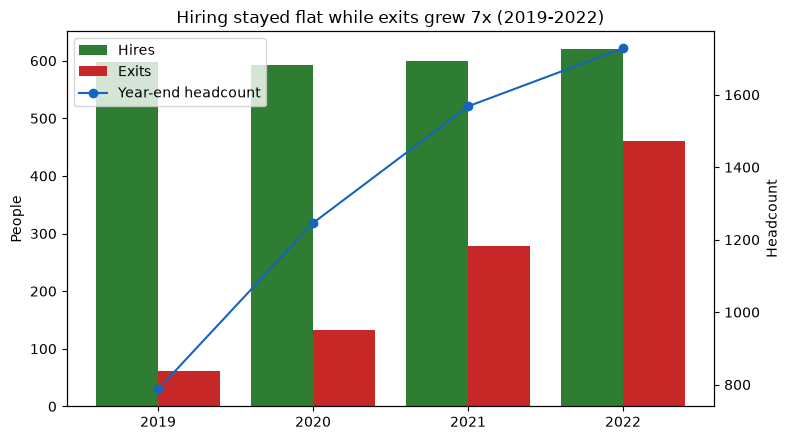

In [3]:
import pandas as pd, matplotlib.pyplot as plt, os
from lifelines import KaplanMeierFitter

emp = pd.read_csv("clean/employee_final.csv", parse_dates=["StartDate", "ExitDate"])
os.makedirs("images", exist_ok=True)

# Yearly table (2019-2022 are full years)
rows = []
for y in range(2019, 2023):
    ye, ps = pd.Timestamp(f"{y}-12-31"), pd.Timestamp(f"{y-1}-12-31")
    hc_end   = ((emp.StartDate <= ye) & (emp.ExitDate.isna() | (emp.ExitDate > ye))).sum()
    hc_start = ((emp.StartDate <= ps) & (emp.ExitDate.isna() | (emp.ExitDate > ps))).sum()
    exits = (emp.ExitDate.dt.year == y).sum()
    rows.append(dict(year=y, hires=(emp.StartDate.dt.year == y).sum(), exits=exits,
                     headcount_end=hc_end, attrition_pct=round(100 * exits / ((hc_start + hc_end) / 2), 1)))
yr = pd.DataFrame(rows)
print(yr)

# Chart 1: hires vs exits, with year-end headcount
fig, ax = plt.subplots(figsize=(8, 4.5))
x = range(len(yr))
ax.bar([i - 0.2 for i in x], yr.hires, 0.4, label="Hires", color="#2E7D32")
ax.bar([i + 0.2 for i in x], yr.exits, 0.4, label="Exits", color="#C62828")
ax.set_xticks(list(x)); ax.set_xticklabels(yr.year); ax.set_ylabel("People")
ax2 = ax.twinx(); ax2.plot(list(x), yr.headcount_end, "o-", color="#1565C0", label="Year-end headcount")
ax2.set_ylabel("Headcount")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
ax.set_title("Hiring stayed flat while exits grew 7x (2019-2022)")
plt.tight_layout(); plt.savefig("images/01_hires_vs_exits.png", dpi=150); plt.show()


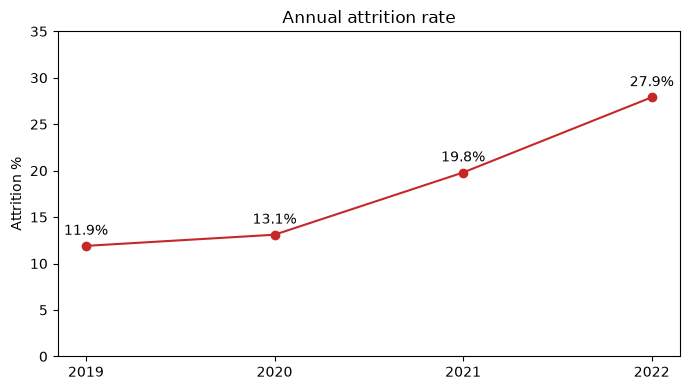

In [4]:
# Chart 2: annual attrition rate
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(yr.year, yr.attrition_pct, "o-", color="#C62828")
for a, b in zip(yr.year, yr.attrition_pct): ax.annotate(f"{b}%", (a, b), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xticks(yr.year); ax.set_ylabel("Attrition %"); ax.set_ylim(0, 35)
ax.set_title("Annual attrition rate")
plt.tight_layout(); plt.savefig("images/02_attrition_rate.png", dpi=150); plt.show()

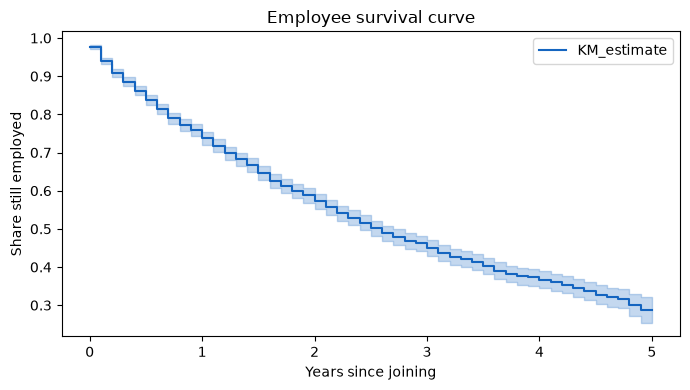

In [6]:
# Chart 3 + unique angle: how long do employees stay? (Kaplan-Meier)
km = KaplanMeierFitter().fit(emp.tenure_yrs, event_observed=emp["left"])
ax = km.plot_survival_function(figsize=(7, 4), color="#1565C0")
ax.set_xlabel("Years since joining"); ax.set_ylabel("Share still employed")
ax.set_title("Employee survival curve")
plt.tight_layout(); plt.savefig("images/03_survival_curve.png", dpi=150); plt.show()


In [7]:
print("Still employed after 1 year:", round(float(km.predict(1)), 3))
print("Still employed after 3 years:", round(float(km.predict(3)), 3))
print("Median tenure (years):", km.median_survival_time_)

Still employed after 1 year: 0.737
Still employed after 3 years: 0.451
Median tenure (years): 2.6


In [8]:
import pandas as pd

emp = pd.read_csv("clean/employee_final.csv", parse_dates=["StartDate", "ExitDate"])

# Group termination types (only for leavers)
emp["exit_group"] = emp.TerminationType.map(
    {"Voluntary": "Voluntary", "Resignation": "Voluntary",
     "Involuntary": "Involuntary", "Retirement": "Retirement"}
).where(emp["left"], "Current")

# Sort helpers: Power BI would sort "<30" last alphabetically
emp["age_band_order"]    = emp.age_band.map({"<30": 1, "30-39": 2, "40-49": 3, "50-59": 4, "60+": 5})
emp["tenure_band_order"] = emp.tenure_band.map({"0-1": 1, "1-3": 2, "3-5": 3, "5+": 4})

# Friendlier names, and drop columns we don't use
emp = emp.rename(columns={"left": "has_left"})
emp["status"] = emp.has_left.map({True: "Left", False: "Current"})
emp = emp.drop(columns=["TerminationDescription", "LocationCode", "Supervisor", "status_conflict"])

emp.to_csv("clean/employee_powerbi.csv", index=False)
print(emp.shape)
print(emp.exit_group.value_counts())

(3000, 28)
exit_group
Current        1467
Voluntary       768
Involuntary     388
Retirement      377
Name: count, dtype: int64


Still employed after 1 year: 0.737
Still employed after 3 years: 0.451
Median tenure (years): 2.6


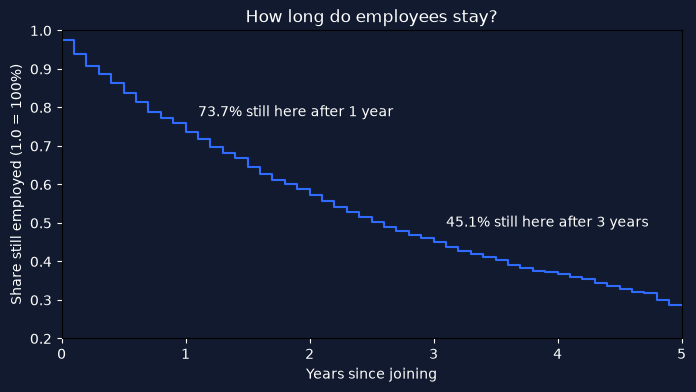

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# load the cleaned employee file
df = pd.read_csv("clean/employee_final.csv")

# fit the survival model
# tenure_yrs = how long each person was at the company
# left = True if they left, False if they are still employed
kmf = KaplanMeierFitter()
kmf.fit(durations=df["tenure_yrs"], event_observed=df["left"])

# numbers I want to show on the chart
one_year = float(kmf.predict(1))
three_year = float(kmf.predict(3))
print("Still employed after 1 year:", round(one_year, 3))
print("Still employed after 3 years:", round(three_year, 3))
print("Median tenure (years):", kmf.median_survival_time_)

# draw the chart (dark background to match the dashboard)
fig, ax = plt.subplots(figsize=(8, 4))
fig.patch.set_facecolor("#111A2E")
ax.set_facecolor("#111A2E")

kmf.plot_survival_function(ax=ax, ci_show=False, legend=False, color="#2F6BFF")

ax.set_title("How long do employees stay?", color="white")
ax.set_xlabel("Years since joining", color="white")
ax.set_ylabel("Share still employed (1.0 = 100%)", color="white")
ax.tick_params(colors="white")
ax.set_xlim(0, 5)
ax.set_ylim(0.2, 1.0)

ax.text(1.1, one_year + 0.04, "73.7% still here after 1 year", color="white")
ax.text(3.1, three_year + 0.04, "45.1% still here after 3 years", color="white")

fig.savefig("images/03_survival_curve_dark.png", dpi=150, facecolor="#111A2E")
plt.show()